# 1. PRAKTIKUM 1: Exploratory Data Analysis (EDA)
**Dataset**: Customer Shopping Trends Dataset
**Link Kaggle**: https://www.kaggle.com/datasets/iamsouravbanerjee/customer-shopping-trends-dataset
**Jumlah Baris x Kolom**: 3900 x 18


In [1]:
# wijdan zayyan sururi_202431007
import pandas as pd
import matplotlib.pyplot as plt

df_eda = pd.read_csv('shopping_trends.csv')
df_eda.head()


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Credit Card,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Bank Transfer,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Cash,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,PayPal,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Cash,Free Shipping,Yes,Yes,31,PayPal,Annually


In [2]:
# wijdan zayyan sururi_202431007
df_eda.info()
print(df_eda.describe())


<class 'pandas.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer ID               3900 non-null   int64  
 1   Age                       3900 non-null   int64  
 2   Gender                    3900 non-null   str    
 3   Item Purchased            3900 non-null   str    
 4   Category                  3900 non-null   str    
 5   Purchase Amount (USD)     3900 non-null   int64  
 6   Location                  3900 non-null   str    
 7   Size                      3900 non-null   str    
 8   Color                     3900 non-null   str    
 9   Season                    3900 non-null   str    
 10  Review Rating             3900 non-null   float64
 11  Subscription Status       3900 non-null   str    
 12  Payment Method            3900 non-null   str    
 13  Shipping Type             3900 non-null   str    
 14  Discount Applied   

In [3]:
# wijdan zayyan sururi_202431007
print(df_eda.isna().sum())
print(df_eda['Category'].unique())


Customer ID                 0
Age                         0
Gender                      0
Item Purchased              0
Category                    0
Purchase Amount (USD)       0
Location                    0
Size                        0
Color                       0
Season                      0
Review Rating               0
Subscription Status         0
Payment Method              0
Shipping Type               0
Discount Applied            0
Promo Code Used             0
Previous Purchases          0
Preferred Payment Method    0
Frequency of Purchases      0
dtype: int64
<StringArray>
['Clothing', 'Footwear', 'Outerwear', 'Accessories']
Length: 4, dtype: str


In [4]:
# wijdan zayyan sururi_202431007
if 'Age' in df_eda.columns and 'Category' in df_eda.columns:
    mean_age = df_eda['Age'].mean()
    modus_cat = df_eda['Category'].mode()[0]
    
    df_eda['Age'] = df_eda['Age'].fillna(mean_age)
    df_eda['Category'] = df_eda['Category'].fillna(modus_cat)


In [5]:
# wijdan zayyan sururi_202431007
print('Jumlah Duplikat:', df_eda.duplicated().sum())
df_eda = df_eda.drop_duplicates()
df_eda.info()


Jumlah Duplikat: 0
<class 'pandas.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer ID               3900 non-null   int64  
 1   Age                       3900 non-null   int64  
 2   Gender                    3900 non-null   str    
 3   Item Purchased            3900 non-null   str    
 4   Category                  3900 non-null   str    
 5   Purchase Amount (USD)     3900 non-null   int64  
 6   Location                  3900 non-null   str    
 7   Size                      3900 non-null   str    
 8   Color                     3900 non-null   str    
 9   Season                    3900 non-null   str    
 10  Review Rating             3900 non-null   float64
 11  Subscription Status       3900 non-null   str    
 12  Payment Method            3900 non-null   str    
 13  Shipping Type             3900 non-null   str    
 14  

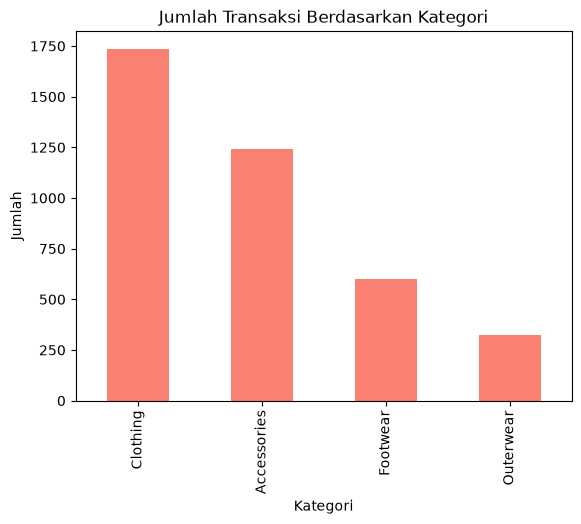

In [6]:
# wijdan zayyan sururi_202431007
df_eda['Category'].value_counts().plot(kind='bar', color='salmon')
plt.title('Jumlah Transaksi Berdasarkan Kategori')
plt.xlabel('Kategori')
plt.ylabel('Jumlah')
plt.show()


# 2. PRAKTIKUM 2: Web Scraping
**Target Situs**: Pokemon Database (Daftar Pokemon berdasarkan Statistik)
**Alamat robots.txt**: https://pokemondb.net/robots.txt

**Penjelasan Robots.txt:** Situs ini memiliki aturan `User-agent: *` dan tidak melakukan `Disallow` pada path `/pokedex/all`. Artinya, data pada halaman tersebut sah dan diizinkan untuk di-*scrape* oleh publik.


In [7]:
# wijdan zayyan sururi_202431007
import requests, csv
import pandas as pd
from bs4 import BeautifulSoup

url = 'https://pokemondb.net/pokedex/all'
headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) Chrome/120.0.0.0'}
response = requests.get(url, headers=headers)
print('Status Code:', response.status_code)

soup = BeautifulSoup(response.text, 'html.parser')


Status Code: 200


In [8]:
# wijdan zayyan sururi_202431007
table = soup.find('table', {'id': 'pokedex'})
rows = table.find('tbody').find_all('tr')
print('Total Data Ditemukan:', len(rows))

result = []
for row in rows:
    cols = row.find_all('td')
    name = cols[1].find('a').get_text(strip=True)
    # Ambil elemen tipe (Primary Type)
    type_ = cols[2].find('a').get_text(strip=True)
    total = cols[3].get_text(strip=True)
    hp = cols[4].get_text(strip=True)
    attack = cols[5].get_text(strip=True)
    defense = cols[6].get_text(strip=True)
    
    result.append({'Name': name, 'Type': type_, 'Total': total, 'HP': hp, 'Attack': attack, 'Defense': defense})

for res in result[:5]:
    print(res)


Total Data Ditemukan: 1261
{'Name': 'Bulbasaur', 'Type': 'Grass', 'Total': '318', 'HP': '45', 'Attack': '49', 'Defense': '49'}
{'Name': 'Ivysaur', 'Type': 'Grass', 'Total': '405', 'HP': '60', 'Attack': '62', 'Defense': '63'}
{'Name': 'Venusaur', 'Type': 'Grass', 'Total': '525', 'HP': '80', 'Attack': '82', 'Defense': '83'}
{'Name': 'Venusaur', 'Type': 'Grass', 'Total': '625', 'HP': '80', 'Attack': '100', 'Defense': '123'}
{'Name': 'Charmander', 'Type': 'Fire', 'Total': '309', 'HP': '39', 'Attack': '52', 'Defense': '43'}


In [9]:
# wijdan zayyan sururi_202431007
with open('pokemon_data.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=['Name', 'Type', 'Total', 'HP', 'Attack', 'Defense'])
    writer.writeheader()
    writer.writerows(result)

df_sc = pd.read_csv('pokemon_data.csv')
print(df_sc.dtypes)
df_sc.head()


Name         str
Type         str
Total      int64
HP         int64
Attack     int64
Defense    int64
dtype: object


,Name,Type,Total,HP,Attack,Defense
0,Bulbasaur,Grass,318,45,49,49
1,Ivysaur,Grass,405,60,62,63
2,Venusaur,Grass,525,80,82,83
3,Venusaur,Grass,625,80,100,123
4,Charmander,Fire,309,39,52,43


# 3. PRAKTIKUM 3: Regresi Linear
**Dataset**: Hasil Scraping Praktikum 2 (Pokemon)
**Target (y)**: Total (Atribut Angka)
**Fitur (x)**: HP, Attack, Defense (Atribut Angka)
**Hubungan**: Masuk akal, karena 'Total' kekuatan Pokemon merupakan hasil akumulasi dari stat 'HP', 'Attack', dan 'Defense' dsb.


In [10]:
# wijdan zayyan sururi_202431007
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

df_reg = pd.read_csv('pokemon_data.csv')
df_reg = df_reg.dropna(subset=['Total', 'HP', 'Attack', 'Defense'])

X = df_reg[['HP', 'Attack', 'Defense']]
y = df_reg['Total']


In [11]:
# wijdan zayyan sururi_202431007
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

model_lr = LinearRegression()
model_lr.fit(X_train, y_train)
y_pred = model_lr.predict(X_test)


In [12]:
# wijdan zayyan sururi_202431007
koef = model_lr.coef_
intersep = model_lr.intercept_
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print('Koefisien:', koef)
print('Intercept:', intersep)
print('MSE:', mse)
print('R2 Score:', r2)
print(f'\nPersamaan Regresi: Y = {intersep:.2f} + {koef[0]:.2f}x1 + {koef[1]:.2f}x2 + {koef[2]:.2f}x3')


Koefisien: [1.63519882 1.51425891 1.35533935]
Intercept: 103.68461518792105
MSE: 3878.5099464902046
R2 Score: 0.7437787509932653

Persamaan Regresi: Y = 103.68 + 1.64x1 + 1.51x2 + 1.36x3


# 4. PRAKTIKUM 4: Decision Tree
**Dataset**: Hasil Scraping Praktikum 2 (Pokemon)
**Target (y)**: Type (Atribut Kategori / Kelas)
**Fitur (x)**: HP, Attack, Defense (Atribut Angka)


In [13]:
# wijdan zayyan sururi_202431007
df_dt = pd.read_csv('pokemon_data.csv')
df_dt.info()
print(df_dt.describe())
print(df_dt.isna().sum())

# Kategori Tipe Pokemon (Grass, Fire, Water, dll)
print('Kelas Target (Type):', df_dt['Type'].unique())


<class 'pandas.DataFrame'>
RangeIndex: 1261 entries, 0 to 1260
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Name     1261 non-null   str  
 1   Type     1261 non-null   str  
 2   Total    1261 non-null   int64
 3   HP       1261 non-null   int64
 4   Attack   1261 non-null   int64
 5   Defense  1261 non-null   int64
dtypes: int64(4), str(2)
memory usage: 59.2 KB
             Total           HP       Attack      Defense
count  1261.000000  1261.000000  1261.000000  1261.000000
mean    449.487708    71.629659    82.458366    75.973830
std     123.770336    26.912735    32.785971    30.984816
min     175.000000     1.000000     5.000000     5.000000
25%     335.000000    55.000000    60.000000    54.000000
50%     471.000000    70.000000    80.000000    70.000000
75%     530.000000    85.000000   103.000000    95.000000
max    1125.000000   255.000000   190.000000   250.000000
Name       0
Type       0
Total      0
HP       

In [14]:
# wijdan zayyan sururi_202431007
from sklearn.preprocessing import LabelEncoder

X_dt = df_dt[['HP', 'Attack', 'Defense']].values.astype(np.float64)

le = LabelEncoder()
y_dt = le.fit_transform(df_dt['Type']).astype(np.int64)


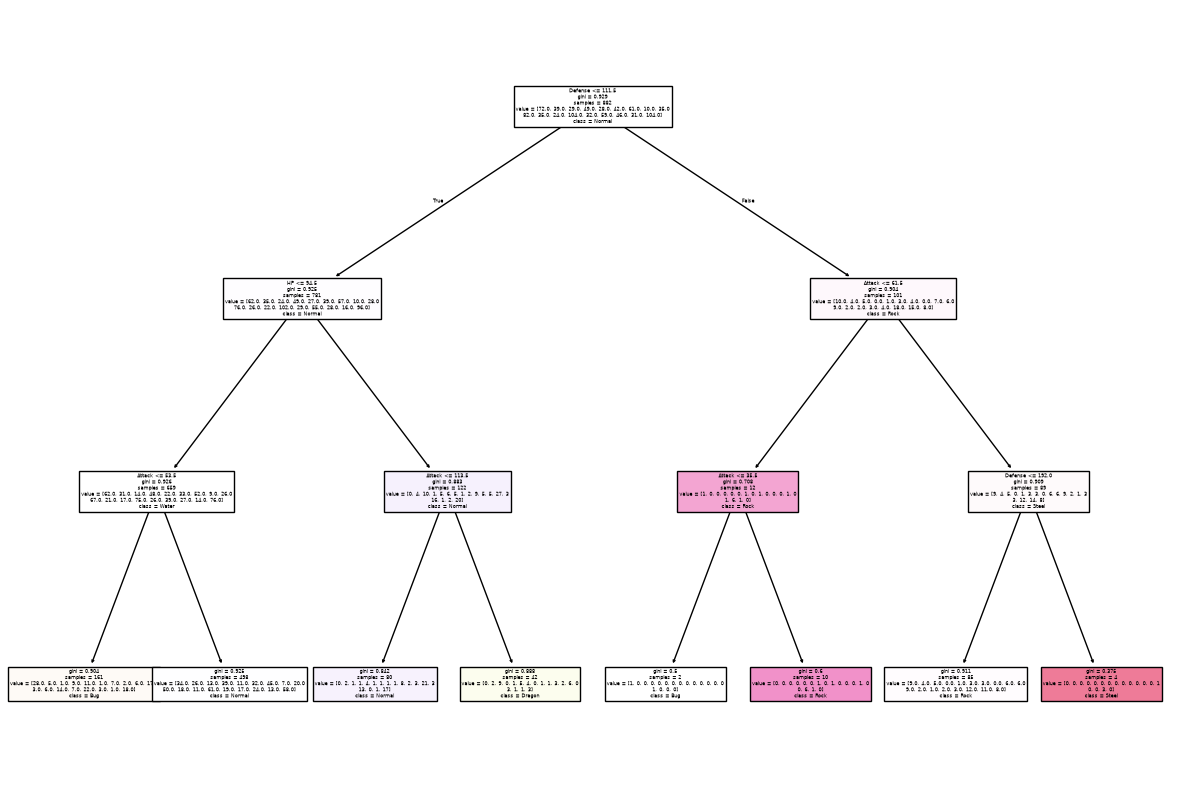

Prediksi Tipe Pokemon Baru: ['Bug']


In [15]:
# wijdan zayyan sururi_202431007
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(X_dt, y_dt, test_size=0.3, random_state=0)
model_dt = DecisionTreeClassifier(max_depth=3)
model_dt.fit(X_train_d, y_train_d)

plt.figure(figsize=(15,10))
plot_tree(model_dt, filled=True, class_names=list(le.classes_), feature_names=['HP', 'Attack', 'Defense'])
plt.show()

# Prediksi pokemon misterius dengan stat [HP, Attack, Defense] = [45, 49, 49]
prediksi_baru = model_dt.predict([[45, 49, 49]])
print('Prediksi Tipe Pokemon Baru:', le.inverse_transform(prediksi_baru))


In [56]:
# wijdan zayyan sururi_202431007
from sklearn.metrics import accuracy_score, classification_report

y_pred_dt = model_dt.predict(X_test_d)
print('Akurasi Sistem:', accuracy_score(y_test_d, y_pred_dt))

kelas_aktif = np.unique(np.concatenate((y_test_d, y_pred_dt)))

nama_kelas_aktif = le.inverse_transform(kelas_aktif)

print('\nClassification Report:\n', classification_report(y_test_d, y_pred_dt, labels=kelas_aktif, target_names=nama_kelas_aktif, zero_division=0))

Akurasi Sistem: 0.10290237467018469

Classification Report:
               precision    recall  f1-score   support

         Bug       0.10      0.33      0.15        21
        Dark       0.00      0.00      0.00        21
      Dragon       0.09      0.08      0.09        25
    Electric       0.00      0.00      0.00        29
       Fairy       0.00      0.00      0.00         6
    Fighting       0.00      0.00      0.00        13
        Fire       0.00      0.00      0.00        19
       Ghost       0.00      0.00      0.00        13
       Grass       0.00      0.00      0.00        35
      Ground       0.00      0.00      0.00        14
         Ice       0.00      0.00      0.00        20
      Normal       0.11      0.84      0.19        31
      Poison       0.00      0.00      0.00        18
     Psychic       0.00      0.00      0.00        25
        Rock       0.09      0.17      0.12        24
       Steel       0.00      0.00      0.00        16
       Water       0

# 5. PRAKTIKUM 5: Naïve Bayes
**Dataset**: Diabetes Prediction Dataset
**Link Kaggle**: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset
**Jumlah Baris x Kolom**: 100000 x 9


In [41]:
!pip install pandas


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [42]:
# wijdan zayyan sururi_202431007
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns

df_nb = pd.read_csv('diabetes_prediction_dataset.csv')
print(df_nb.head())
df_nb.info()
print(df_nb.describe())


   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  
3          5.0                  155         0  
4          4.8                  155         0  
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 n

In [45]:
# wijdan zayyan sururi_202431007
from sklearn.preprocessing import LabelEncoder

num_cols = df_nb.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df_nb.select_dtypes(include=['object', 'str']).columns.tolist()
print('Kolom Numerik:', num_cols)
print('Kolom Kategorik:', cat_cols)

le_nb = LabelEncoder()
for c in cat_cols:
    print('Nilai Unik', c, ':', df_nb[c].unique())
    df_nb[c] = le_nb.fit_transform(df_nb[c])
print(df_nb.head(3))



Kolom Numerik: ['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']
Kolom Kategorik: []
   gender   age  hypertension  heart_disease  smoking_history    bmi  \
0       0  80.0             0              1                4  25.19   
1       0  54.0             0              0                0  27.32   
2       1  28.0             0              0                4  27.32   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  


In [49]:
# wijdan zayyan sururi_202431007
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

X_nb = df_nb.drop('diabetes', axis=1)
y_nb = df_nb['diabetes']

X_train_nb, X_test_nb, y_train_nb, y_test_nb = train_test_split(X_nb, y_nb, test_size=0.25, random_state=0)
model_nb = GaussianNB()
model_nb.fit(X_train_nb, y_train_nb)


,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[68605., 6395.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.91,0.09]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.657e-06
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['gender','age','hypertension',...,'bmi','HbA1c_level', 'blood_glucose_level']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 8)","[[ 0.41, 40.17, 0.06,..., 26.91, 5.4 ,132.75], [ 0.47, 61.01, 0.24,..., 32.02, 6.94,193.95]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 8)","[[ 0.24, 498.01, 0.06,..., 41. , 0.95,1170.89], [ 0.25, 213.02, 0.18,..., 57.26, 1.15,3444.72]]"


Evaluasi Training:
               precision    recall  f1-score   support

           0       0.97      0.93      0.95     68605
           1       0.46      0.65      0.54      6395

    accuracy                           0.90     75000
   macro avg       0.71      0.79      0.74     75000
weighted avg       0.92      0.90      0.91     75000



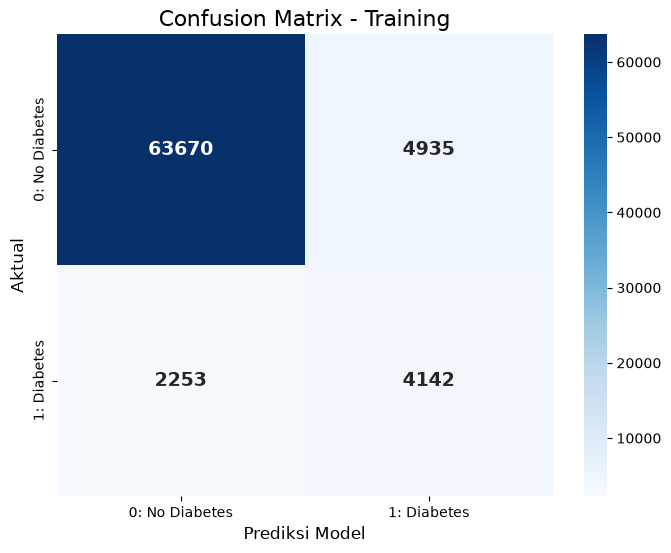

In [52]:
# wijdan zayyan sururi_202431007
from sklearn.metrics import confusion_matrix, classification_report

y_pred_train = model_nb.predict(X_train_nb)
print('Evaluasi Training:\n', classification_report(y_train_nb, y_pred_train))

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_train_nb, y_pred_train), annot=True, fmt='d', cmap='Blues', 
            xticklabels=['0: No Diabetes', '1: Diabetes'], yticklabels=['0: No Diabetes', '1: Diabetes'],
            annot_kws={'size': 14, 'weight': 'bold'})
plt.title('Confusion Matrix - Training', fontsize=16)
plt.xlabel('Prediksi Model', fontsize=12)
plt.ylabel('Aktual', fontsize=12)
plt.show()


Evaluasi Testing:
               precision    recall  f1-score   support

           0       0.97      0.93      0.95     22895
           1       0.45      0.65      0.53      2105

    accuracy                           0.90     25000
   macro avg       0.71      0.79      0.74     25000
weighted avg       0.92      0.90      0.91     25000



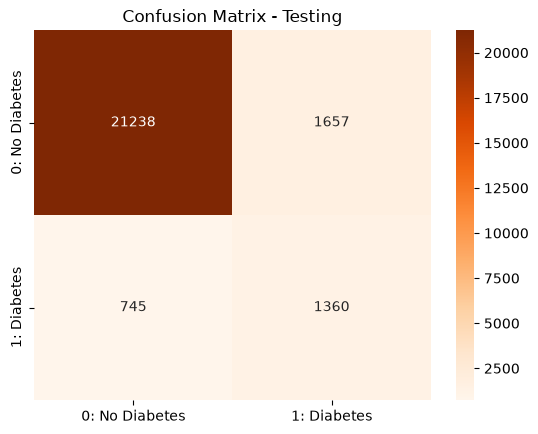

Hasil Diagnosa (1=Diabetes): 1


In [54]:
# wijdan zayyan sururi_202431007

y_pred_test = model_nb.predict(X_test_nb)
cm_test = confusion_matrix(y_test_nb, y_pred_test)
print('Evaluasi Testing:\n', classification_report(y_test_nb, y_pred_test))

sns.heatmap(cm_test, annot=True, fmt='d', cmap='Oranges', xticklabels=['0: No Diabetes', '1: Diabetes'], yticklabels=['0: No Diabetes', '1: Diabetes'])
plt.title('Confusion Matrix - Testing')
plt.show()

data_pasien = pd.DataFrame([[1, 55, 1, 0, 4, 30.5, 6.8, 140]], columns=X_test_nb.columns)
pred_akhir = model_nb.predict(data_pasien)
print('Hasil Diagnosa (1=Diabetes):', pred_akhir[0])